<a href="https://colab.research.google.com/github/VSGopiChanduNeelam/CT_TASK_06_POST_PROCESSING/blob/main/post_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================================
# SYNTHETIC 3D CT DENOISING DATASET GENERATOR
# Google Colab
# ============================================================

import numpy as np
import json
import shutil
from pathlib import Path

# ============================================================
# 1. CONFIGURATION
# ============================================================

NUM_VOLUMES = 500
VOLUME_SHAPE = (142, 232, 194)  # Z, Y, X
NOISE_LEVEL = 0.04
SEED = 42

OUTPUT_DIR = Path("/content/ct_denoising_dataset")

# Estimated storage needed for float16 clean/noisy pairs
estimated_gb = (
    NUM_VOLUMES
    * np.prod(VOLUME_SHAPE)
    * 2             # clean + noisy
    * 2             # float16 = 2 bytes
    / 1e9
)

total, used, free = shutil.disk_usage("/content")

print(f"Available disk space: {free / 1e9:.2f} GB")
print(f"Estimated dataset size: {estimated_gb:.2f} GB")

if free / 1e9 < estimated_gb * 1.10:
    raise RuntimeError(
        "Insufficient disk space. Reduce NUM_VOLUMES or free disk space."
    )

rng = np.random.default_rng(SEED)

# Create output folders
for split in ["train", "val", "test"]:
    (OUTPUT_DIR / split / "clean").mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_DIR / split / "noisy").mkdir(
        parents=True, exist_ok=True
    )

# ============================================================
# 2. GENERATE SYNTHETIC 3D PHANTOM
# ============================================================

def generate_clean_volume(shape, rng):

    z, y, x = np.ogrid[
        :shape[0],
        :shape[1],
        :shape[2]
    ]

    volume = np.zeros(shape, dtype=np.float32)

    def ellipsoid(center, radius):
        return (
            ((z - center[0]) / radius[0]) ** 2
            + ((y - center[1]) / radius[1]) ** 2
            + ((x - center[2]) / radius[2]) ** 2
        ) <= 1

    # Body phantom
    body_center = (
        shape[0] * 0.5,
        shape[1] * 0.5,
        shape[2] * 0.5
    )

    body_radius = (
        shape[0] * rng.uniform(0.35, 0.42),
        shape[1] * rng.uniform(0.35, 0.42),
        shape[2] * rng.uniform(0.35, 0.42)
    )

    body = ellipsoid(body_center, body_radius)
    volume[body] = 0.020

    # Two lung-like regions
    for side in [-1, 1]:

        lung_center = (
            shape[0] * rng.uniform(0.47, 0.55),
            shape[1] * rng.uniform(0.47, 0.55),
            shape[2] * (0.5 + side * 0.18)
        )

        lung_radius = (
            shape[0] * rng.uniform(0.22, 0.30),
            shape[1] * rng.uniform(0.22, 0.30),
            shape[2] * rng.uniform(0.10, 0.14)
        )

        lung = ellipsoid(lung_center, lung_radius)

        volume[lung & body] = rng.uniform(0.004, 0.009)

    # Bone-like structures
    for _ in range(rng.integers(3, 8)):

        bone_center = (
            shape[0] * rng.uniform(0.25, 0.75),
            shape[1] * rng.uniform(0.25, 0.75),
            shape[2] * rng.uniform(0.30, 0.70)
        )

        bone_radius = (
            shape[0] * rng.uniform(0.02, 0.05),
            shape[1] * rng.uniform(0.02, 0.05),
            shape[2] * rng.uniform(0.02, 0.05)
        )

        bone = ellipsoid(bone_center, bone_radius)
        volume[bone & body] = rng.uniform(0.030, 0.045)

    return volume


# ============================================================
# 3. ADD GAUSSIAN NOISE
# ============================================================

def generate_noisy_volume(clean, rng):

    sigma = NOISE_LEVEL * max(float(clean.max()), 1e-6)

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=clean.shape
    ).astype(np.float32)

    noisy = clean + noise

    return np.clip(noisy, 0, None)


# ============================================================
# 4. SPLIT DATASET: 70% / 15% / 15%
# ============================================================

indices = rng.permutation(NUM_VOLUMES)

train_end = int(NUM_VOLUMES * 0.70)
val_end = int(NUM_VOLUMES * 0.85)

train_ids = set(indices[:train_end])
val_ids = set(indices[train_end:val_end])
test_ids = set(indices[val_end:])

counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

# ============================================================
# 5. GENERATE AND SAVE VOLUME PAIRS
# ============================================================

for i in range(NUM_VOLUMES):

    local_rng = np.random.default_rng(SEED + i + 1000)

    clean = generate_clean_volume(
        VOLUME_SHAPE,
        local_rng
    )

    noisy = generate_noisy_volume(
        clean,
        local_rng
    )

    if i in train_ids:
        split = "train"
    elif i in val_ids:
        split = "val"
    else:
        split = "test"

    # Save in float16 to reduce disk usage
    clean = clean.astype(np.float16)
    noisy = noisy.astype(np.float16)

    clean_path = (
        OUTPUT_DIR / split / "clean" / f"volume_{i:04d}.npy"
    )
    noisy_path = (
        OUTPUT_DIR / split / "noisy" / f"volume_{i:04d}.npy"
    )

    np.save(clean_path, clean)
    np.save(noisy_path, noisy)

    counts[split] += 1

    if (i + 1) % 10 == 0 or (i + 1) == NUM_VOLUMES:
        print(
            f"Generated {i + 1}/{NUM_VOLUMES} | "
            f"Train: {counts['train']} | "
            f"Val: {counts['val']} | "
            f"Test: {counts['test']}"
        )

    del clean, noisy


# ============================================================
# 6. SAVE METADATA
# ============================================================

metadata = {
    "total_volumes": NUM_VOLUMES,
    "volume_shape_zyx": list(VOLUME_SHAPE),
    "noise_level": NOISE_LEVEL,
    "data_type": "float16",
    "dataset_type": "synthetic phantom",
    "noise_model": "additive Gaussian noise in image domain",
    "split_ratio": {
        "train": 0.70,
        "val": 0.15,
        "test": 0.15
    },
    "splits": counts,
    "seed": SEED
}

with open(OUTPUT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)


# ============================================================
# 7. VERIFY DATASET
# ============================================================

print("\n" + "=" * 55)
print("DATASET GENERATION COMPLETED")
print("=" * 55)

print("Dataset location:", OUTPUT_DIR)
print("Training volumes:", counts["train"])
print("Validation volumes:", counts["val"])
print("Testing volumes:", counts["test"])
print("Volume shape:", VOLUME_SHAPE)

# Check one saved pair
sample_clean_path = next(
    (OUTPUT_DIR / "train" / "clean").glob("*.npy")
)

sample_noisy_path = (
    OUTPUT_DIR / "train" / "noisy" / sample_clean_path.name
)

sample_clean = np.load(sample_clean_path)
sample_noisy = np.load(sample_noisy_path)

print("\nSample clean shape:", sample_clean.shape)
print("Sample noisy shape:", sample_noisy.shape)
print("Clean dtype:", sample_clean.dtype)
print("Noisy dtype:", sample_noisy.dtype)
print("Pair shapes match:", sample_clean.shape == sample_noisy.shape)

print("\nRemaining disk space:",
      f"{shutil.disk_usage('/content').free / 1e9:.2f} GB")


Available disk space: 62.68 GB
Estimated dataset size: 12.78 GB
Generated 10/500 | Train: 7 | Val: 2 | Test: 1
Generated 20/500 | Train: 11 | Val: 4 | Test: 5
Generated 30/500 | Train: 17 | Val: 6 | Test: 7
Generated 40/500 | Train: 22 | Val: 7 | Test: 11
Generated 50/500 | Train: 28 | Val: 7 | Test: 15
Generated 60/500 | Train: 37 | Val: 7 | Test: 16
Generated 70/500 | Train: 44 | Val: 10 | Test: 16
Generated 80/500 | Train: 50 | Val: 13 | Test: 17
Generated 90/500 | Train: 58 | Val: 15 | Test: 17
Generated 100/500 | Train: 65 | Val: 17 | Test: 18
Generated 110/500 | Train: 70 | Val: 19 | Test: 21
Generated 120/500 | Train: 74 | Val: 23 | Test: 23
Generated 130/500 | Train: 80 | Val: 25 | Test: 25
Generated 140/500 | Train: 87 | Val: 25 | Test: 28
Generated 150/500 | Train: 95 | Val: 26 | Test: 29
Generated 160/500 | Train: 104 | Val: 27 | Test: 29
Generated 170/500 | Train: 111 | Val: 27 | Test: 32
Generated 180/500 | Train: 118 | Val: 29 | Test: 33
Generated 190/500 | Train: 124 | V

In [ ]:

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(1, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)

        self.pool = nn.MaxPool3d(2)

        self.up2 = nn.ConvTranspose3d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(64, 32)

        self.up1 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(32, 16)

        self.out = nn.Conv3d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        d2 = self.up2(e3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


model = UNet3D().to(device)

print("Model initialized successfully.")
print("Device:", device)


Model initialized successfully.
Device: cuda


In [ ]:

import numpy as np
import torch
import torch.nn as nn
import time
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

ROOT = Path("/content/ct_denoising_dataset")
PATCH_SIZE = 64
BATCH_SIZE = 2
EPOCHS = 5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

class CTVolumeDataset(Dataset):
    def __init__(self, split, patches_per_volume=2):
        self.clean_files = sorted(
            (ROOT / split / "clean").glob("*.npy")
        )
        self.noisy_dir = ROOT / split / "noisy"
        self.patches_per_volume = patches_per_volume

        if not self.clean_files:
            raise FileNotFoundError(f"No clean volumes found in {split}")

        for f in self.clean_files:
            if not (self.noisy_dir / f.name).exists():
                raise FileNotFoundError(f"Missing noisy pair: {f.name}")

    def __len__(self):
        return len(self.clean_files) * self.patches_per_volume

    def __getitem__(self, idx):
        i = idx % len(self.clean_files)
        clean_path = self.clean_files[i]
        noisy_path = self.noisy_dir / clean_path.name

        clean = np.load(clean_path, mmap_mode="r")
        noisy = np.load(noisy_path, mmap_mode="r")

        z, y, x = clean.shape
        p = PATCH_SIZE

        z0 = np.random.randint(z - p + 1)
        y0 = np.random.randint(y - p + 1)
        x0 = np.random.randint(x - p + 1)

        clean_patch = np.array(
            clean[z0:z0+p, y0:y0+p, x0:x0+p],
            dtype=np.float32, copy=True
        )
        noisy_patch = np.array(
            noisy[z0:z0+p, y0:y0+p, x0:x0+p],
            dtype=np.float32, copy=True
        )

        # Match the normalization to the data range
        clean_patch /= 0.05
        noisy_patch /= 0.05

        return (
            torch.from_numpy(noisy_patch[None]),
            torch.from_numpy(clean_patch[None])
        )

train_ds = CTVolumeDataset("train", patches_per_volume=2)
val_ds = CTVolumeDataset("val", patches_per_volume=1)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True
)

print("Training patches:", len(train_ds))
print("Mini-batches per epoch:", len(train_loader))
print("Validation patches:", len(val_ds))


Device: cuda
GPU: Tesla T4
Training patches: 1000
Mini-batches per epoch: 500
Validation patches: 75


Clean shape: (142, 232, 194)
Noisy shape: (142, 232, 194)
Clean range: 0.0 to 0.042419434
Noisy range: 0.0 to 0.048828125
Matching shapes: True


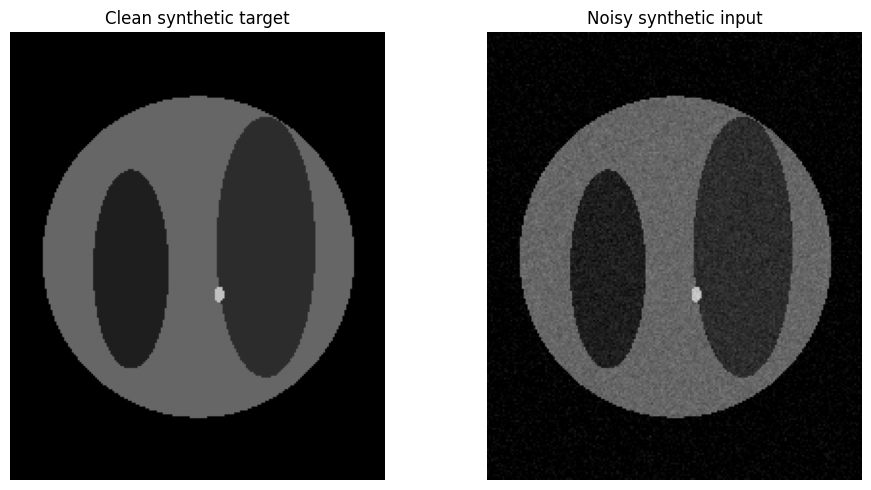

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATASET = Path("/content/ct_denoising_dataset")

# Find one matching noisy/clean pair from the test split
clean_files = sorted((DATASET / "test" / "clean").glob("*.npy"))

if not clean_files:
    raise FileNotFoundError(
        "No test volumes found. Run the dataset-generation cell first."
    )

clean_path = clean_files[0]
noisy_path = DATASET / "test" / "noisy" / clean_path.name

clean = np.load(clean_path).astype(np.float32)
noisy = np.load(noisy_path).astype(np.float32)

print("Clean shape:", clean.shape)
print("Noisy shape:", noisy.shape)
print("Clean range:", clean.min(), "to", clean.max())
print("Noisy range:", noisy.min(), "to", noisy.max())
print("Matching shapes:", clean.shape == noisy.shape)

# Display the central axial slice
z = clean.shape[0] // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(clean[z], cmap="gray", vmin=0, vmax=0.05)
axes[0].set_title("Clean synthetic target")

axes[1].imshow(noisy[z], cmap="gray", vmin=0, vmax=0.05)
axes[1].set_title("Noisy synthetic input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_val_loss = float("inf")
SAVE_PATH = "/content/best_ct_unet3d.pth"

for epoch in range(EPOCHS):
    start = time.time()
    model.train()
    total_train_loss = 0.0

    for batch_idx, (noisy, clean) in enumerate(train_loader):
        noisy = noisy.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            output = model(noisy)
            loss = criterion(output, clean)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_train_loss += loss.item()

    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for noisy, clean in val_loader:
            noisy = noisy.to(device, non_blocking=True)
            clean = clean.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                output = model(noisy)
                loss = criterion(output, clean)

            total_val_loss += loss.item()

    train_loss = total_train_loss / len(train_loader)
    val_loss = total_val_loss / len(val_loader)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)

    elapsed = (time.time() - start) / 60

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Time: {elapsed:.2f} min"
    )

print("Best model saved to:", SAVE_PATH)


Epoch 1/5 | Train Loss: 0.001410 | Val Loss: 0.000539 | Time: 0.71 min
Epoch 2/5 | Train Loss: 0.000175 | Val Loss: 0.000080 | Time: 0.62 min
Epoch 3/5 | Train Loss: 0.000070 | Val Loss: 0.000052 | Time: 0.59 min
Epoch 4/5 | Train Loss: 0.000073 | Val Loss: 0.000049 | Time: 0.54 min
Epoch 5/5 | Train Loss: 0.000055 | Val Loss: 0.000033 | Time: 0.54 min
Best model saved to: /content/best_ct_unet3d.pth


In [ ]:

from pathlib import Path
import torch

model_path = Path("/content/best_ct_unet3d.pth")

if model_path.exists():
    print("Model saved successfully!")
    print(f"Model size: {model_path.stat().st_size / (1024**2):.2f} MB")
else:
    print("Model file not found. Check the training output.")


Model saved successfully!
Model size: 1.30 MB


In [ ]:

import numpy as np
import torch
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)
model.eval()

test_ds = CTVolumeDataset("test", patches_per_volume=1)

test_loader = torch.utils.data.DataLoader(
    test_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

psnr_values = []
ssim_values = []

with torch.no_grad():
    for noisy, clean in test_loader:
        noisy = noisy.to(device)
        clean = clean.to(device)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            prediction = model(noisy)

        pred = prediction.float().cpu().numpy()[0, 0]
        target = clean.cpu().numpy()[0, 0]

        # Inputs and targets were normalized by 0.05
        pred *= 0.05
        target *= 0.05

        pred = np.clip(pred, 0, None)
        target = np.clip(target, 0, None)

        psnr_values.append(
            peak_signal_noise_ratio(target, pred, data_range=0.05)
        )
        ssim_values.append(
            structural_similarity(target, pred, data_range=0.05)
        )

print(f"Mean test PSNR: {np.mean(psnr_values):.3f} dB")
print(f"Mean test SSIM: {np.mean(ssim_values):.4f}")


Mean test PSNR: 48.505 dB
Mean test SSIM: 0.9976


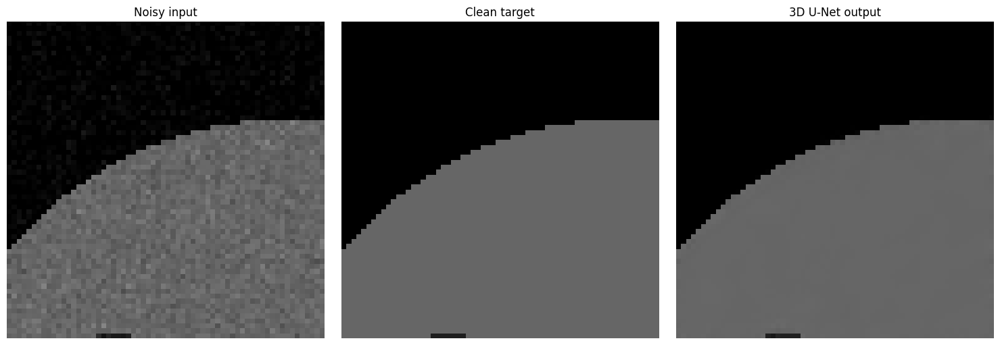

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

noisy, clean = test_ds[0]

with torch.no_grad():
    x = noisy.unsqueeze(0).to(device)

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):
        prediction = model(x)

noisy_np = noisy[0].numpy() * 0.05
clean_np = clean[0].numpy() * 0.05
pred_np = prediction.float().cpu().numpy()[0, 0] * 0.05

# Display the middle axial slice
mid = noisy_np.shape[0] // 2
vmin, vmax = 0.0, 0.05

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(noisy_np[mid], cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Noisy input")

axes[1].imshow(clean_np[mid], cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Clean target")

axes[2].imshow(pred_np[mid], cmap="gray", vmin=vmin, vmax=vmax)
axes[2].set_title("3D U-Net output")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import numpy as np

recon_path = Path("/content/reconstructed_chest_volume_3d.npy")
model_path = Path("/content/best_ct_unet3d.pth")

print("Model exists:", model_path.exists())
print("Reconstruction exists:", recon_path.exists())

if recon_path.exists():
    volume = np.load(recon_path, mmap_mode="r")
    print("Reconstruction shape:", volume.shape)
    print("Data type:", volume.dtype)
    print("Intensity range:", float(volume.min()), float(volume.max()))


Model exists: True
Reconstruction exists: False


In [ ]:

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

matches = []

for root in search_roots:
    if root.exists():
        for path in root.rglob("reconstructed_chest_volume_3d.npy"):
            matches.append(path)

if matches:
    print("Found reconstruction file:")
    for path in matches:
        print(path)
else:
    print("Reconstruction file not found in searched locations.")
    print("Check whether helical_recon.py has been run successfully.")


Reconstruction file not found in searched locations.
Check whether helical_recon.py has been run successfully.


In [ ]:

from pathlib import Path
from google.colab import files

model_path = Path("/content/best_ct_unet3d.pth")
input_path = Path("/content/reconstructed_volume.npy")

if not model_path.exists():
    raise FileNotFoundError(
        "Model weights missing. Upload best_ct_unet3d.pth."
    )

if not input_path.exists():
    print("Upload your reconstructed .npy file now.")
    uploaded = files.upload()

    for name in uploaded:
        if name.endswith(".npy"):
            input_path = Path("/content") / name
            break

if not input_path.exists():
    raise FileNotFoundError("No reconstructed .npy file found.")

import numpy as np

volume = np.load(input_path, mmap_mode="r")
print("Model found:", model_path.exists())
print("Input file:", input_path)
print("Volume shape:", volume.shape)
print("Intensity range:", float(volume.min()), float(volume.max()))


Model found: True
Input file: /content/reconstructed_volume.npy
Volume shape: (256, 175, 256)
Intensity range: 0.0 0.051447927951812744


In [ ]:

import numpy as np
import torch
import torch.nn as nn
from pathlib import Path

MODEL_PATH = "/content/best_ct_unet3d.pth"
OUTPUT_PATH = "/content/denoised_chest_volume_3d.npy"

PATCH = 64
STRIDE = 32
SCALE = 0.05

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


# Same architecture used during training
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(1, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.pool = nn.MaxPool3d(2)
        self.up2 = nn.ConvTranspose3d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(64, 32)
        self.up1 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(32, 16)
        self.out = nn.Conv3d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        d2 = self.dec2(torch.cat([self.up2(e3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


model = UNet3D().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()
print("Trained model loaded.")


# Load reconstruction
volume = np.asarray(np.load(input_path), dtype=np.float32)

if volume.ndim != 3:
    raise ValueError(f"Expected 3D volume, got {volume.shape}")

if not np.isfinite(volume).all():
    raise ValueError("Input contains NaN or Inf.")

original_shape = volume.shape

# Pad dimensions smaller than patch size
pad = [(0, max(0, PATCH - s)) for s in volume.shape]
volume = np.pad(volume, pad, mode="edge")
Z, Y, X = volume.shape

def patch_starts(size, patch, stride):
    positions = list(range(0, size - patch + 1, stride))
    if positions[-1] != size - patch:
        positions.append(size - patch)
    return positions

zs = patch_starts(Z, PATCH, STRIDE)
ys = patch_starts(Y, PATCH, STRIDE)
xs = patch_starts(X, PATCH, STRIDE)

# Weighted blending reduces seams between patches
w1 = np.hanning(PATCH + 2)[1:-1].astype(np.float32)
weights = (
    w1[:, None, None] *
    w1[None, :, None] *
    w1[None, None, :]
)
weights = np.maximum(weights, 1e-3)

prediction_sum = np.zeros(volume.shape, dtype=np.float32)
weight_sum = np.zeros(volume.shape, dtype=np.float32)

total = len(zs) * len(ys) * len(xs)
count = 0

with torch.inference_mode():
    for z in zs:
        for y in ys:
            for x in xs:
                patch = volume[
                    z:z+PATCH, y:y+PATCH, x:x+PATCH
                ].copy()

                # Must match training normalization
                patch /= SCALE
                tensor = torch.from_numpy(patch)[None, None].to(device)

                # Use float32 inference for numerical robustness
                pred = model(tensor).float()[0, 0].cpu().numpy()
                pred *= SCALE

                prediction_sum[
                    z:z+PATCH, y:y+PATCH, x:x+PATCH
                ] += pred * weights

                weight_sum[
                    z:z+PATCH, y:y+PATCH, x:x+PATCH
                ] += weights

                count += 1
                if count % 10 == 0 or count == total:
                    print(f"Processed {count}/{total} patches")

denoised = prediction_sum / np.maximum(weight_sum, 1e-8)

# Restore original dimensions
denoised = denoised[
    :original_shape[0],
    :original_shape[1],
    :original_shape[2]
]

np.save(OUTPUT_PATH, denoised.astype(np.float32))

print("\nDenoising finished.")
print("Output:", OUTPUT_PATH)
print("Shape:", denoised.shape)
print("Intensity range:", float(denoised.min()), float(denoised.max()))


Using: cuda
Trained model loaded.
Processed 10/245 patches
Processed 20/245 patches
Processed 30/245 patches
Processed 40/245 patches
Processed 50/245 patches
Processed 60/245 patches
Processed 70/245 patches
Processed 80/245 patches
Processed 90/245 patches
Processed 100/245 patches
Processed 110/245 patches
Processed 120/245 patches
Processed 130/245 patches
Processed 140/245 patches
Processed 150/245 patches
Processed 160/245 patches
Processed 170/245 patches
Processed 180/245 patches
Processed 190/245 patches
Processed 200/245 patches
Processed 210/245 patches
Processed 220/245 patches
Processed 230/245 patches
Processed 240/245 patches
Processed 245/245 patches

Denoising finished.
Output: /content/denoised_chest_volume_3d.npy
Shape: (256, 175, 256)
Intensity range: -0.005116115789860487 0.035300612449645996


In [ ]:

import matplotlib.pyplot as plt

original = np.asarray(np.load(input_path), dtype=np.float32)
result = np.load(OUTPUT_PATH)

slice_idx = original.shape[0] // 2

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

vmin = min(float(original.min()), float(result.min()))
vmax = max(float(original.max()), float(result.max()))

ax[0].imshow(original[slice_idx], cmap="gray", vmin=vmin, vmax=vmax)
ax[0].set_title("Original reconstruction")
ax[1].imshow(result[slice_idx], cmap="gray", vmin=vmin, vmax=vmax)
ax[1].set_title("3D U-Net output")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

input_path = Path("/content/reconstructed_volume.npy")
output_path = Path("/content/denoised_chest_volume_3d.npy")

if not input_path.exists():
    raise FileNotFoundError(
        f"Input volume not found: {input_path}. Check your actual uploaded filename."
    )

if not output_path.exists():
    raise FileNotFoundError(
        "Denoised output not found. Run the denoising cell first."
    )

original = np.load(input_path)
denoised = np.load(output_path)

print("Original shape:", original.shape)
print("Denoised shape:", denoised.shape)
print("Shapes match:", original.shape == denoised.shape)
print("Output contains only finite values:", np.isfinite(denoised).all())
print("Output range:", denoised.min(), "to", denoised.max())

# Display the middle slice
slice_idx = original.shape[0] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

vmin = min(float(original.min()), float(denoised.min()))
vmax = max(float(original.max()), float(denoised.max()))

axes[0].imshow(original[slice_idx], cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original reconstruction")

axes[1].imshow(denoised[slice_idx], cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Denoised reconstruction")

axes[2].imshow(
    np.abs(original[slice_idx] - denoised[slice_idx]),
    cmap="hot"
)
axes[2].set_title("Absolute difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Original shape: (256, 175, 256)
Denoised shape: (256, 175, 256)
Shapes match: True
Output contains only finite values: True
Output range: -0.005116116 to 0.035300612


In [ ]:

import numpy as np

original = np.asarray(np.load(input_path), dtype=np.float32)
denoised = np.asarray(np.load(output_path), dtype=np.float32)

difference = denoised - original

print("Original mean:", float(original.mean()))
print("Denoised mean:", float(denoised.mean()))
print("Original standard deviation:", float(original.std()))
print("Denoised standard deviation:", float(denoised.std()))
print("Mean absolute change:", float(np.mean(np.abs(difference))))
print("Minimum denoised value:", float(denoised.min()))
print("Negative output voxels:", int(np.sum(denoised < 0)))
print("Negative voxel percentage:", float(np.mean(denoised < 0) * 100), "%")


Original mean: 0.00010157567157875746
Denoised mean: -3.62605533155147e-05
Original standard deviation: 0.0005895278882235289
Denoised standard deviation: 0.0005991336074657738
Mean absolute change: 0.00014124237350188196
Minimum denoised value: -0.005116115789860487
Negative output voxels: 11416625
Negative voxel percentage: 99.54507010323661 %


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

original = np.asarray(np.load(input_path), dtype=np.float32)
denoised = np.asarray(np.load(output_path), dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

idx = original.shape[0] // 2

vmin = min(float(original.min()), float(denoised.min()))
vmax = max(float(original.max()), float(denoised.max()))

axes[0].imshow(original[idx], cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original reconstruction")

axes[1].imshow(denoised[idx], cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Current model output")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original percentiles:",
      np.percentile(original, [0, 1, 50, 95, 99, 100]))
print("Denoised percentiles:",
      np.percentile(denoised, [0, 1, 50, 95, 99, 100]))


Original percentiles: [0.00000000e+00 0.00000000e+00 8.05372547e-05 2.01041799e-04
 3.79288065e-04 5.14479280e-02]
Denoised percentiles: [-5.11611579e-03 -1.02397826e-04 -6.25124449e-05 -5.51141784e-05
 -3.97569927e-05  3.53006124e-02]


In [ ]:

import numpy as np
import torch

model.eval()
noisy, clean = test_ds[0]

with torch.no_grad():
    x = noisy.unsqueeze(0).to(device)
    pred = model(x).float().cpu().numpy()[0, 0]

noisy_np = noisy[0].numpy()
clean_np = clean[0].numpy()
pred = pred * 0.05

print("Synthetic clean range:",
      float(clean_np.min() * 0.05),
      float(clean_np.max() * 0.05))

print("Synthetic noisy range:",
      float(noisy_np.min() * 0.05),
      float(noisy_np.max() * 0.05))

print("Model prediction range:",
      float(pred.min()), float(pred.max()))

print("Negative prediction percentage:",
      float(np.mean(pred < 0) * 100), "%")


Synthetic clean range: 0.0 0.03448486328125
Synthetic noisy range: 0.0 0.0389404296875
Model prediction range: -0.0016881704796105623 0.03710915148258209
Negative prediction percentage: 23.061752319335938 %


In [ ]:

# ============================================================
# SELF-SUPERVISED 3D CT DENOISING BASELINE
# Uses one reconstructed volume; no clean target required
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
import time

# -------------------- CONFIGURATION -------------------------

INPUT_PATH = Path("/content/reconstructed_volume.npy")
MODEL_PATH = Path("/content/self_supervised_ct_denoiser.pth")
OUTPUT_PATH = Path("/content/self_supervised_denoised_volume.npy")

PATCH = 64
STEPS_PER_EPOCH = 100
EPOCHS = 5
LR = 1e-4
MASK_RATE = 0.05

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Upload the reconstruction to Colab first: {INPUT_PATH}"
    )

# -------------------- LOAD VOLUME --------------------------

volume = np.asarray(np.load(INPUT_PATH), dtype=np.float32)

if volume.ndim != 3 or not np.isfinite(volume).all():
    raise ValueError("Input must be a finite 3D volume.")

original_shape = volume.shape

# Robust scaling for optimization.
# The same scale is reversed when saving the output.
scale = float(np.percentile(np.abs(volume), 99.5))
if scale < 1e-10:
    raise ValueError("Volume intensity scale is too close to zero.")

normalized = volume / scale

print("Input shape:", original_shape)
print("Normalization scale:", scale)
print("Normalized range:",
      float(normalized.min()), float(normalized.max()))

# -------------------- MODEL -------------------------------

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(1, 8)
        self.enc2 = ConvBlock(8, 16)
        self.enc3 = ConvBlock(16, 32)
        self.pool = nn.MaxPool3d(2)

        self.up2 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec2 = ConvBlock(32, 16)
        self.up1 = nn.ConvTranspose3d(16, 8, 2, stride=2)
        self.dec1 = ConvBlock(16, 8)
        self.out = nn.Conv3d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        d2 = self.up2(e3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


model = UNet3D().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# -------------------- MASKING FUNCTION ---------------------
# Replace selected voxels by an average of their six neighbours.
# The model is penalized only at the replaced positions.

def make_masked_input(x):
    mask = torch.rand_like(x) < MASK_RATE

    neighbour_mean = (
        torch.roll(x, 1, dims=2)
        + torch.roll(x, -1, dims=2)
        + torch.roll(x, 1, dims=3)
        + torch.roll(x, -1, dims=3)
        + torch.roll(x, 1, dims=4)
        + torch.roll(x, -1, dims=4)
    ) / 6.0

    masked_x = torch.where(mask, neighbour_mean, x)
    return masked_x, mask


# -------------------- TRAINING PATCHES ---------------------

def get_random_patch():
    z, y, x = normalized.shape
    p = PATCH

    starts = [
        np.random.randint(max(1, dim - p + 1))
        for dim in (z, y, x)
    ]

    z0, y0, x0 = starts
    patch = normalized[
        z0:z0+p, y0:y0+p, x0:x0+p
    ].copy()

    return torch.from_numpy(patch)[None, None].float()


# -------------------- SELF-SUPERVISED TRAINING -------------

best_loss = float("inf")

for epoch in range(EPOCHS):
    start = time.time()
    model.train()
    losses = []

    for step in range(STEPS_PER_EPOCH):
        target = get_random_patch().to(device)
        model_input, mask = make_masked_input(target)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(model_input)

        # Train only at masked positions
        if mask.any():
            loss = (
                (prediction - target).square() * mask
            ).sum() / mask.sum().clamp_min(1)
        else:
            continue

        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    mean_loss = float(np.mean(losses))

    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model.state_dict(), MODEL_PATH)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Masked loss: {mean_loss:.6f} | "
        f"Time: {(time.time()-start)/60:.2f} min"
    )

print("Training finished:", MODEL_PATH)

# -------------------- OVERLAPPING-PATCH INFERENCE ----------

model.load_state_dict(torch.load(
    MODEL_PATH, map_location=device, weights_only=True
))
model.eval()

padded = np.pad(
    normalized,
    [(0, max(0, PATCH-s)) for s in normalized.shape],
    mode="edge"
)

Z, Y, X = padded.shape
STRIDE = 32

def starts_for(dim):
    positions = list(range(0, dim-PATCH+1, STRIDE))
    if positions[-1] != dim-PATCH:
        positions.append(dim-PATCH)
    return positions

zs, ys, xs = map(starts_for, (Z, Y, X))

axis = np.hanning(PATCH+2)[1:-1].astype(np.float32)
weight = np.maximum(
    axis[:, None, None] *
    axis[None, :, None] *
    axis[None, None, :],
    1e-3
)

pred_sum = np.zeros(padded.shape, dtype=np.float32)
weight_sum = np.zeros(padded.shape, dtype=np.float32)
total = len(zs) * len(ys) * len(xs)
done = 0

with torch.inference_mode():
    for z0 in zs:
        for y0 in ys:
            for x0 in xs:
                patch = padded[
                    z0:z0+PATCH, y0:y0+PATCH, x0:x0+PATCH
                ].copy()

                tensor = torch.from_numpy(patch)[None, None].to(device)
                pred = model(tensor)[0, 0].cpu().numpy()

                pred_sum[
                    z0:z0+PATCH, y0:y0+PATCH, x0:x0+PATCH
                ] += pred * weight

                weight_sum[
                    z0:z0+PATCH, y0:y0+PATCH, x0:x0+PATCH
                ] += weight

                done += 1
                if done % 20 == 0 or done == total:
                    print(f"Inference: {done}/{total} patches")

result = pred_sum / np.maximum(weight_sum, 1e-8)
result = result[
    :original_shape[0],
    :original_shape[1],
    :original_shape[2]
]

# Original input is nonnegative; enforce nonnegative output.
result = np.maximum(result * scale, 0).astype(np.float32)

np.save(OUTPUT_PATH, result)

print("\nSaved:", OUTPUT_PATH)
print("Output shape:", result.shape)
print("Output range:", float(result.min()), float(result.max()))

# -------------------- VISUAL COMPARISON ---------------------

mid = original_shape[0] // 2
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

vmin = float(np.percentile(volume, 1))
vmax = float(np.percentile(volume, 99.5))

axes[0].imshow(volume[mid], cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original reconstruction")

axes[1].imshow(result[mid], cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Self-supervised output")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Device: cuda
Input shape: (256, 175, 256)
Normalization scale: 0.0008462672703899443
Normalized range: 0.0 60.793949127197266
Epoch 1/5 | Masked loss: 0.040743 | Time: 0.28 min
Epoch 2/5 | Masked loss: 0.075381 | Time: 0.27 min
Epoch 3/5 | Masked loss: 0.010483 | Time: 0.27 min
Epoch 4/5 | Masked loss: 0.024098 | Time: 0.26 min
Epoch 5/5 | Masked loss: 0.057405 | Time: 0.26 min
Training finished: /content/self_supervised_ct_denoiser.pth
Inference: 20/245 patches
Inference: 40/245 patches
Inference: 60/245 patches
Inference: 80/245 patches
Inference: 100/245 patches
Inference: 120/245 patches
Inference: 140/245 patches
Inference: 160/245 patches
Inference: 180/245 patches
Inference: 200/245 patches
Inference: 220/245 patches
Inference: 240/245 patches
Inference: 245/245 patches

Saved: /content/self_supervised_denoised_volume.npy
Output shape: (256, 175, 256)
Output range: 0.0 0.011154212057590485


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_PATH = Path("/content/reconstructed_volume.npy")
OUTPUT_PATH = Path("/content/self_supervised_denoised_volume.npy")

if not INPUT_PATH.exists() or not OUTPUT_PATH.exists():
    raise FileNotFoundError(
        "Run the self-supervised training and inference cell first."
    )

original = np.asarray(np.load(INPUT_PATH), dtype=np.float32)
denoised = np.asarray(np.load(OUTPUT_PATH), dtype=np.float32)

assert original.shape == denoised.shape, "Volume shapes do not match!"
assert np.isfinite(denoised).all(), "Output contains NaN or Inf!"

print("Shape:", denoised.shape)
print("Original range:", original.min(), original.max())
print("Denoised range:", denoised.min(), denoised.max())
print("Mean absolute change:",
      float(np.mean(np.abs(original - denoised))))

# Compare three axial slices
indices = [original.shape[0] // 4,
           original.shape[0] // 2,
           3 * original.shape[0] // 4]

vmin = float(np.percentile(original, 1))
vmax = float(np.percentile(original, 99.5))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, idx in enumerate(indices):
    axes[row, 0].imshow(
        original[idx], cmap="gray", vmin=vmin, vmax=vmax
    )
    axes[row, 0].set_title(f"Original — slice {idx}")

    axes[row, 1].imshow(
        denoised[idx], cmap="gray", vmin=vmin, vmax=vmax
    )
    axes[row, 1].set_title("Self-supervised output")

    axes[row, 2].imshow(
        np.abs(original[idx] - denoised[idx]), cmap="hot"
    )
    axes[row, 2].set_title("Absolute difference")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


Shape: (256, 175, 256)
Original range: 0.0 0.051447928
Denoised range: 0.0 0.011154212
Mean absolute change: 6.209290586411953e-05


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

for name, volume in [("Original", original), ("Denoised", denoised)]:
    print(f"\n{name}")
    print("Min:", np.min(volume))
    print("Max:", np.max(volume))
    print("Mean:", np.mean(volume))
    print("Std:", np.std(volume))
    print("Percentiles:", np.percentile(volume, [50, 90, 95, 99, 99.5, 99.9]))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(original.ravel()[::20], bins=100)
plt.title("Original intensity distribution")
plt.xlabel("Intensity")

plt.subplot(1, 2, 2)
plt.hist(denoised.ravel()[::20], bins=100)
plt.title("Denoised intensity distribution")
plt.xlabel("Intensity")

plt.tight_layout()
plt.show()


Original
Min: 0.0
Max: 0.051447928
Mean: 0.00010157567
Std: 0.0005895279
Percentiles: [8.05372547e-05 1.50283876e-04 2.01041799e-04 3.79288065e-04
 8.46267515e-04 1.39370913e-02]

Denoised
Min: 0.0
Max: 0.011154212
Mean: 8.6527514e-05
Std: 0.0003562718
Percentiles: [6.62128987e-05 1.02100668e-04 1.27025256e-04 2.19700081e-04
 4.43371248e-04 7.81227825e-03]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

# Find the original volume's brightest voxel
idx = np.unravel_index(np.argmax(original), original.shape)
z, y, x = idx

print("Brightest voxel (z, y, x):", idx)
print("Original intensity:", original[idx])
print("Denoised intensity:", denoised[idx])

# Inspect the corresponding axial slice
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original[z], cmap="gray")
axes[0].set_title(f"Original — slice {z}")

axes[1].imshow(denoised[z], cmap="gray")
axes[1].set_title(f"Denoised — slice {z}")

axes[2].imshow(np.abs(original[z] - denoised[z]), cmap="inferno")
axes[2].set_title("Absolute difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Brightest voxel (z, y, x): (np.int64(255), np.int64(0), np.int64(2))
Original intensity: 0.051447928
Denoised intensity: 0.00096246006


In [ ]:
import numpy as np

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

# Compare the brightest voxels
for name, volume in [("Original", original), ("Denoised", denoised)]:
    flat_idx = np.argpartition(volume.ravel(), -10)[-10:]
    flat_idx = flat_idx[np.argsort(volume.ravel()[flat_idx])[::-1]]

    print(f"\n{name}: top 10 voxels")
    for i in flat_idx:
        coord = np.unravel_index(i, volume.shape)
        print(coord, float(volume[coord]))

# Compare interior and boundary intensity statistics
boundary = np.zeros(original.shape, dtype=bool)
boundary[[0, -1], :, :] = True
boundary[:, [0, -1], :] = True
boundary[:, :, [0, -1]] = True

for name, volume in [("Original", original), ("Denoised", denoised)]:
    print(f"\n{name}")
    print("Boundary maximum:", float(volume[boundary].max()))
    print("Interior maximum:", float(volume[~boundary].max()))
    print("Boundary 99th percentile:",
          float(np.percentile(volume[boundary], 99)))


Original: top 10 voxels
(np.int64(255), np.int64(0), np.int64(2)) 0.051447927951812744
(np.int64(247), np.int64(0), np.int64(0)) 0.04848303645849228
(np.int64(246), np.int64(0), np.int64(0)) 0.04806473106145859
(np.int64(106), np.int64(0), np.int64(0)) 0.04803360626101494
(np.int64(255), np.int64(0), np.int64(1)) 0.04783026874065399
(np.int64(108), np.int64(0), np.int64(0)) 0.04757151007652283
(np.int64(107), np.int64(0), np.int64(0)) 0.04719274491071701
(np.int64(105), np.int64(0), np.int64(0)) 0.04710286483168602
(np.int64(104), np.int64(0), np.int64(0)) 0.0467446967959404
(np.int64(255), np.int64(0), np.int64(3)) 0.04570138454437256

Denoised: top 10 voxels
(np.int64(117), np.int64(5), np.int64(137)) 0.011154212057590485
(np.int64(119), np.int64(5), np.int64(137)) 0.01114652305841446
(np.int64(113), np.int64(5), np.int64(123)) 0.011146442033350468
(np.int64(121), np.int64(5), np.int64(139)) 0.011142096482217312
(np.int64(115), np.int64(5), np.int64(121)) 0.011141226626932621
(np.in

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

# Use a shared intensity scale for a fair comparison
vmin = 0
vmax = np.percentile(original, 99.9)

slices = [original.shape[0] // 4,
          original.shape[0] // 2,
          3 * original.shape[0] // 4]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, z in enumerate(slices):
    axes[row, 0].imshow(original[z], cmap="gray",
                        vmin=vmin, vmax=vmax)
    axes[row, 0].set_title(f"Original — z={z}")

    axes[row, 1].imshow(denoised[z], cmap="gray",
                        vmin=vmin, vmax=vmax)
    axes[row, 1].set_title(f"Denoised — z={z}")

    axes[row, 2].imshow(
        np.abs(original[z] - denoised[z]), cmap="inferno"
    )
    axes[row, 2].set_title("Absolute difference")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

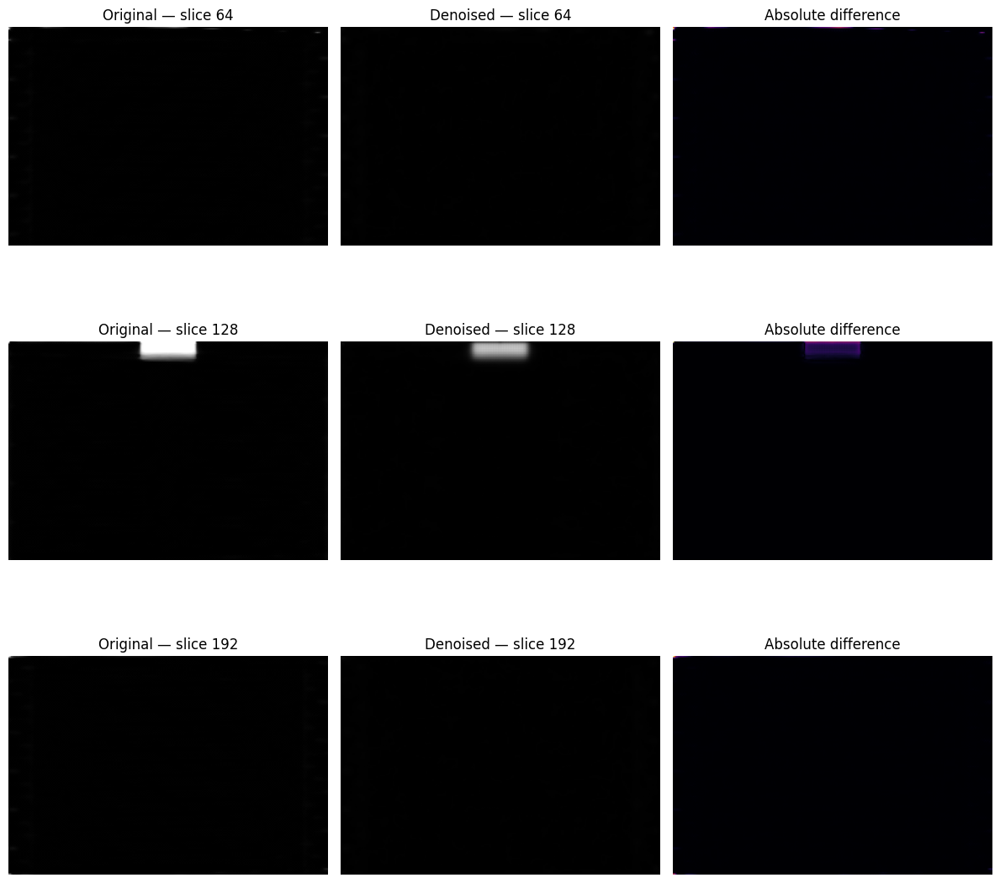

Saved image to /content/ct_comparison.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

vmax = np.percentile(original, 99.9)
slices = [
    original.shape[0] // 4,
    original.shape[0] // 2,
    3 * original.shape[0] // 4
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, z in enumerate(slices):
    axes[row, 0].imshow(original[z], cmap="gray", vmin=0, vmax=vmax)
    axes[row, 0].set_title(f"Original — slice {z}")

    axes[row, 1].imshow(denoised[z], cmap="gray", vmin=0, vmax=vmax)
    axes[row, 1].set_title(f"Denoised — slice {z}")

    axes[row, 2].imshow(
        np.abs(original[z] - denoised[z]), cmap="inferno"
    )
    axes[row, 2].set_title("Absolute difference")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("/content/ct_comparison.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

print("Saved image to /content/ct_comparison.png")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

slices = [64, 128, 192]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, z in enumerate(slices):
    orig = original[z]
    den = denoised[z]

    # Separate contrast scaling for visualization only
    orig_max = np.percentile(orig, 99.5)
    den_max = np.percentile(den, 99.5)

    axes[row, 0].imshow(
        orig, cmap="gray", vmin=0, vmax=max(orig_max, 1e-8)
    )
    axes[row, 0].set_title(f"Original — slice {z}")

    axes[row, 1].imshow(
        den, cmap="gray", vmin=0, vmax=max(den_max, 1e-8)
    )
    axes[row, 1].set_title(f"Denoised — slice {z}")

    diff = np.abs(orig - den)
    diff_max = np.percentile(diff, 99.5)

    axes[row, 2].imshow(
        diff, cmap="inferno", vmin=0, vmax=max(diff_max, 1e-8)
    )
    axes[row, 2].set_title("Difference")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("/content/ct_comparison_contrast.png", dpi=150)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

vol = np.load("/content/reconstructed_volume.npy")
den = np.load("/content/self_supervised_denoised_volume.npy")

print("Volume shape:", vol.shape)
print("Finite values:", np.isfinite(vol).all())
print("Original percentiles:",
      np.percentile(vol, [0, 50, 90, 95, 99, 99.5, 99.9, 100]))

# Find the slice with the highest standard deviation
slice_std = np.std(vol, axis=(1, 2))
z = int(np.argmax(slice_std))

print("Slice with highest variation:", z)
print("Slice standard deviation:", slice_std[z])
print("Slice min/max:", vol[z].min(), vol[z].max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use the same robust scale for original and denoised
vmax = np.percentile(vol, 99.5)
vmax = max(float(vmax), 1e-8)

axes[0].imshow(vol[z], cmap="gray", vmin=0, vmax=vmax)
axes[0].set_title(f"Original slice {z}")

axes[1].imshow(den[z], cmap="gray",
               vmin=0, vmax=max(float(np.percentile(den[z], 99.5)), 1e-8))
axes[1].set_title(f"Denoised slice {z}")

axes[2].imshow(vol[z], cmap="gray",
               vmin=np.percentile(vol[z], 1),
               vmax=max(float(np.percentile(vol[z], 99)), 1e-8))
axes[2].set_title("Original — enhanced contrast")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Volume shape: (256, 175, 256)
Finite values: True
Original percentiles: [0.00000000e+00 8.05372547e-05 1.50283876e-04 2.01041799e-04
 3.79288065e-04 8.46267515e-04 1.39370913e-02 5.14479280e-02]
Slice with highest variation: 127
Slice standard deviation: 0.0014952591
Slice min/max: 0.0 0.032727934


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

z = 127
a = original[z]
b = denoised[z]

# Exclude the outer 5 pixels from the display
a_inner = a[5:-5, 5:-5]
b_inner = b[5:-5, 5:-5]

# Set separate display limits using interior intensities
vmax_a = np.percentile(a_inner, 99.5)
vmax_b = np.percentile(b_inner, 99.5)

print("Original interior display maximum:", vmax_a)
print("Denoised interior display maximum:", vmax_b)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(a_inner, cmap="gray", vmin=0, vmax=max(vmax_a, 1e-8))
axes[0].set_title("Original — slice 127")

axes[1].imshow(b_inner, cmap="gray", vmin=0, vmax=max(vmax_b, 1e-8))
axes[1].set_title("Denoised — slice 127")

axes[2].imshow(
    np.abs(a_inner - b_inner),
    cmap="inferno",
    vmin=0,
    vmax=max(float(np.percentile(np.abs(a_inner - b_inner), 99.5)), 1e-8)
)
axes[2].set_title("Absolute difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Original interior display maximum: 0.01212363
Denoised interior display maximum: 0.007695252


Selected slice: 127
Display limits: 0.0 0.012123638098128147
Nonzero fraction: 0.5727455357142858


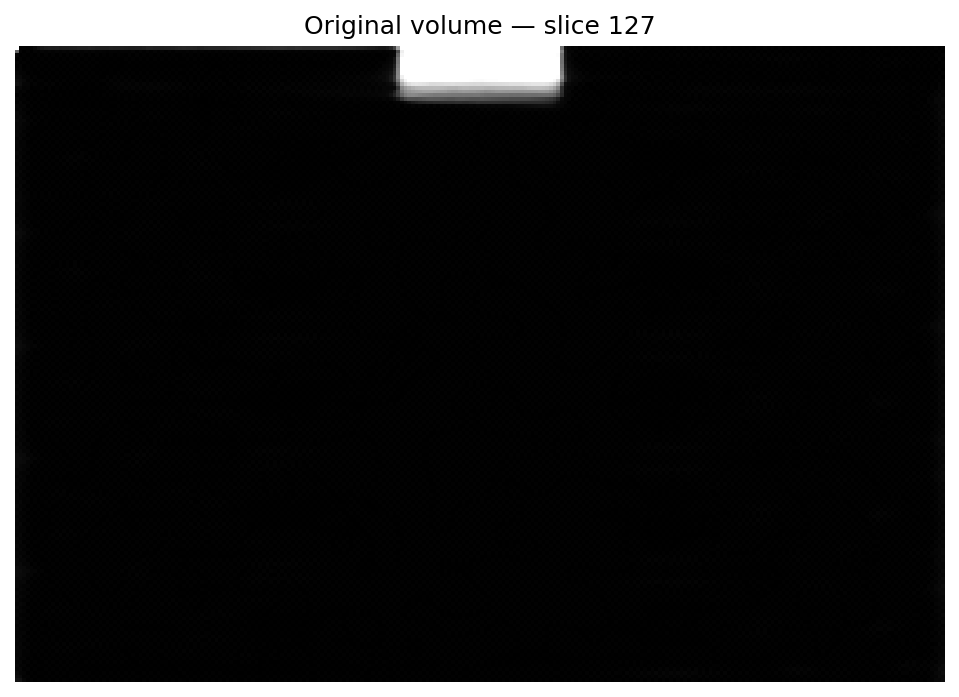

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

vol = np.load("/content/reconstructed_volume.npy")

# Choose the slice with the highest variation
z = int(np.argmax(np.std(vol, axis=(1, 2))))
img = vol[z]

# Robust contrast scaling, excluding the outer 5-pixel border
inner = img[5:-5, 5:-5]
lo, hi = np.percentile(inner, [1, 99.5])

print("Selected slice:", z)
print("Display limits:", lo, hi)
print("Nonzero fraction:", np.mean(img != 0))

# Save a contrast-enhanced image
plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray", vmin=lo, vmax=hi)
plt.title(f"Original volume — slice {z}")
plt.axis("off")
plt.savefig(
    "/content/ct_slice_debug.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)
plt.close()

display(Image(filename="/content/ct_slice_debug.png"))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

vol = np.load("/content/reconstructed_volume.npy")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# View the central plane of each axis
views = [
    (vol[vol.shape[0] // 2, :, :], "Axis 0 fixed"),
    (vol[:, vol.shape[1] // 2, :], "Axis 1 fixed"),
    (vol[:, :, vol.shape[2] // 2], "Axis 2 fixed"),
]

for ax, (img, title) in zip(axes, views):
    lo, hi = np.percentile(img, [1, 99.5])
    ax.imshow(img, cmap="gray", vmin=lo, vmax=max(hi, lo + 1e-8))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/ct_three_axes.png", dpi=150, bbox_inches="tight")
plt.show()

Image saved. File size: 474642 bytes


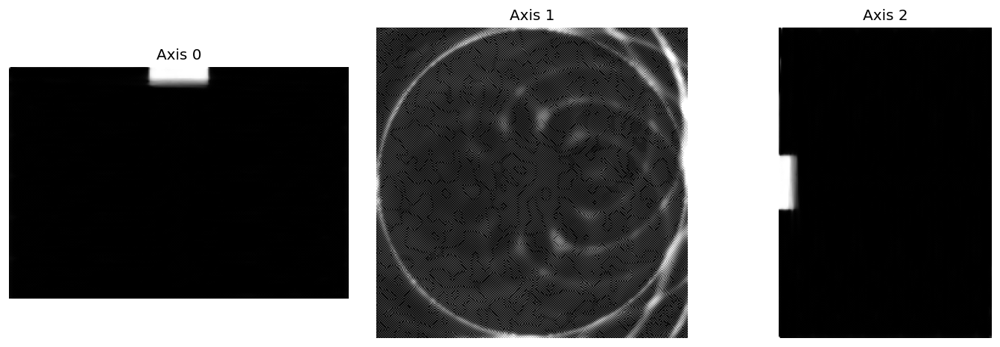

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Image

vol = np.load("/content/reconstructed_volume.npy")

# Create three central views
views = [
    vol[vol.shape[0] // 2, :, :],
    vol[:, vol.shape[1] // 2, :],
    vol[:, :, vol.shape[2] // 2],
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, title in zip(
    axes, views, ["Axis 0", "Axis 1", "Axis 2"]
):
    lo, hi = np.percentile(img, [1, 99.5])
    if hi <= lo:
        hi = lo + 1e-8

    ax.imshow(img, cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
fig.savefig("/content/ct_three_axes.png", dpi=120, bbox_inches="tight")
plt.close(fig)

print("Image saved. File size:",
      __import__("os").path.getsize("/content/ct_three_axes.png"), "bytes")

display(Image(filename="/content/ct_three_axes.png"))

In [ ]:
import numpy as np

original = np.load("/content/reconstructed_volume.npy")
denoised = np.load("/content/self_supervised_denoised_volume.npy")

# Analyze the cross-sectional plane along Axis 1
y = 87
a = original[:, y, :]
b = denoised[:, y, :]

# Exclude a 10-pixel border for interior analysis
a_inner = a[10:-10, 10:-10]
b_inner = b[10:-10, 10:-10]

print("Interior standard deviation:")
print("Original:", float(a_inner.std()))
print("Denoised:", float(b_inner.std()))

print("\nInterior mean absolute change:",
      float(np.mean(np.abs(a_inner - b_inner))))

print("\nInterior correlation:",
      float(np.corrcoef(a_inner.ravel(), b_inner.ravel())[0, 1]))

print("\nIntensity retained (99th percentile):")
print("Original:", float(np.percentile(a_inner, 99)))
print("Denoised:", float(np.percentile(b_inner, 99)))

Interior standard deviation:
Original: 6.506593490485102e-05
Denoised: 2.4368742742808536e-05

Interior mean absolute change: 4.1123836126644164e-05

Interior correlation: 0.8730868370028916

Intensity retained (99th percentile):
Original: 0.0002411719033261761
Denoised: 0.0001477565965615213


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Load your reconstructed 3D CT volume
volume = np.load("/content/reconstructed_volume.npy")

print("Volume shape:", volume.shape)

# Select the middle slice along Axis 1
slice_index = volume.shape[1] // 2
ct_slice = volume[:, slice_index, :]

print("CT slice shape:", ct_slice.shape)
print("Intensity range:", ct_slice.min(), ct_slice.max())

# Improve display contrast without changing the original data
vmin, vmax = np.percentile(ct_slice, [1, 99.5])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(ct_slice, cmap="gray", vmin=vmin, vmax=vmax)
ax.set_title(f"Reconstructed CT — slice {slice_index}")
ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/content/complete_ct_slice.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Volume shape: (256, 175, 256)
CT slice shape: (256, 256)
Intensity range: 0.0 0.0010647438


In [ ]:
import numpy as np

v = np.load("/content/reconstructed_volume.npy").astype(np.float32)

print("Shape:", v.shape)
print("Dtype:", v.dtype)
print("Finite values:", np.isfinite(v).mean() * 100, "%")
print("Min / max:", np.nanmin(v), np.nanmax(v))
print("Mean / std:", np.nanmean(v), np.nanstd(v))
print("Nonzero fraction:", np.count_nonzero(v) / v.size)

print("\nPercentiles:")
for p in [0, 1, 10, 50, 90, 95, 99, 99.5, 99.9, 100]:
    print(f"{p:5.1f}%: {np.nanpercentile(v, p):.8g}")

print("\nAxis-wise maximum absolute signal:")
for axis in range(3):
    other_axes = tuple(i for i in range(3) if i != axis)
    profile = np.max(np.abs(v), axis=other_axes)
    print(
        f"Axis {axis}: length={len(profile)}, "
        f"min={profile.min():.6g}, max={profile.max():.6g}, "
        f"median={np.median(profile):.6g}"
    )

Shape: (256, 175, 256)
Dtype: float32
Finite values: 100.0 %
Min / max: 0.0 0.051447928
Mean / std: 0.00010157567 0.0005895279
Nonzero fraction: 0.5987103271484375

Percentiles:
  0.0%: 0
  1.0%: 0
 10.0%: 0
 50.0%: 8.0537255e-05
 90.0%: 0.00015028387
 95.0%: 0.0002010418
 99.0%: 0.00037928805
 99.5%: 0.00084626727
 99.9%: 0.013937053
100.0%: 0.051447928

Axis-wise maximum absolute signal:
Axis 0: length=256, min=0.00500652, max=0.0514479, median=0.0193337
Axis 1: length=175, min=0.000538555, max=0.0514479, median=0.000697172
Axis 2: length=256, min=0.00455643, max=0.0514479, median=0.0153399


In [ ]:

!pip -q install plotly scipy

import numpy as np
import plotly.graph_objects as go
from scipy.ndimage import gaussian_filter, median_filter
from IPython.display import display

# -------------------------------------------------
# 1. Create a synthetic 3D chest-like phantom
# -------------------------------------------------
np.random.seed(42)
D, H, W = 64, 128, 128

z, y, x = np.mgrid[-1:1:complex(D),
                   -1:1:complex(H),
                   -1:1:complex(W)]

body = (x / 0.88)**2 + (y / 0.91)**2 < 1
left_lung = ((x + 0.34)**2 / 0.20**2 +
             (y + 0.02)**2 / 0.68**2) < 1
right_lung = ((x - 0.34)**2 / 0.20**2 +
              (y + 0.02)**2 / 0.68**2) < 1

clean = np.zeros((D, H, W), dtype=np.float32)
clean[body] = 0.55
clean[left_lung & body] = 0.16
clean[right_lung & body] = 0.16

# Synthetic central soft tissue and vertebral structure
heart = ((x / 0.23)**2 + ((y - 0.18) / 0.30)**2) < 1
spine = (x**2 + ((y + 0.68) / 0.13)**2) < 0.02
clean[heart & body] = 0.68
clean[spine & body] = 0.95

# Small vessel-like structures inside lungs
vessels = np.exp(-((x * 12)**2 + (y * 4)**2))
vessels *= (left_lung | right_lung)
clean += (0.10 * vessels).astype(np.float32)
clean *= body

# -------------------------------------------------
# 2. Simulate artifacts for demonstration only
# -------------------------------------------------
noisy = clean + np.random.normal(0, 0.035, clean.shape)

radius = np.sqrt(x**2 + y**2)
ring_pattern = 0.045 * np.sin(75 * radius)
noisy += ring_pattern.astype(np.float32) * body
noisy = np.clip(noisy, 0, 1).astype(np.float32)

# -------------------------------------------------
# 3. Demonstration post-processing
# -------------------------------------------------
processed = median_filter(noisy, size=3)
processed = gaussian_filter(processed, sigma=0.7)

# -------------------------------------------------
# 4. Show axial slices side by side
# -------------------------------------------------
mid = D // 2

fig = go.Figure()
fig.add_trace(go.Heatmap(
    z=noisy[mid], colorscale="Gray",
    zmin=0, zmax=1, showscale=False,
    xaxis="x", yaxis="y"
))
fig.add_trace(go.Heatmap(
    z=processed[mid], colorscale="Gray",
    zmin=0, zmax=1, showscale=False,
    xaxis="x2", yaxis="y2"
))

fig.update_layout(
    grid=dict(rows=1, columns=2, pattern="independent"),
    yaxis=dict(autorange="reversed", scaleanchor="x"),
    yaxis2=dict(autorange="reversed", scaleanchor="x2"),
    width=1000, height=480
)
fig.show()

# -------------------------------------------------
# 5. Interactive 3D volume rendering
# -------------------------------------------------
# Render the synthetic body surface
fig3d = go.Figure(data=go.Isosurface(
    x=x[::2, ::2, ::2].ravel(),
    y=y[::2, ::2, ::2].ravel(),
    z=z[::2, ::2, ::2].ravel(),
    value=processed[::2, ::2, ::2].ravel(),
    isomin=0.40,
    isomax=0.75,
    surface_count=3,
    colorscale="Gray",
    caps=dict(x_show=False, y_show=False, z_show=False)
))
fig3d.update_layout(
    scene=dict(aspectmode="data"),
    width=800, height=650
)
fig3d.show()

# Save synthetic demonstration volumes
np.save("/content/synthetic_noisy_demo.npy", noisy)
np.save("/content/synthetic_postprocessed_demo.npy", processed)


